Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RKWS plots: 59
KNP plots : 40
RKWS embedding:
  2021: 1 embedding tile(s), UTM zone(s): ['46N']
KNP embedding:
  2022: 1 embedding tile(s), UTM zone(s): ['46N']
RKWS: 59 plots extracted
KNP: 40 plots extracted
Train: 47 plots | Test: 12 plots
Test cluster IDs (compare with the Sentinel-2 run): [4, 5, 6, 13, 14, 31, 42, 45, 46, 51, 56, 58]
Train PAR LAI range: 0.35 - 4.29 | mean 2.17
Test PAR LAI range : 0.33 - 3.62 | mean 2.17
Total hyperparameter combinations to test: 40
  20/40 done (0.1 min)
  40/40 done (0.2 min)

Top 5 combinations by LOOCV RMSE (KNN, AlphaEarth):
 n_neighbors  weights    metric  scale  loocv_rmse
           7 distance    cosine  False    0.833196
           9 distance    cosine  False    0.833605
           9 distance euclidean  False    0.835584
           7 distance euclidean  False    0.837700
           9  uniform euclidean  False  

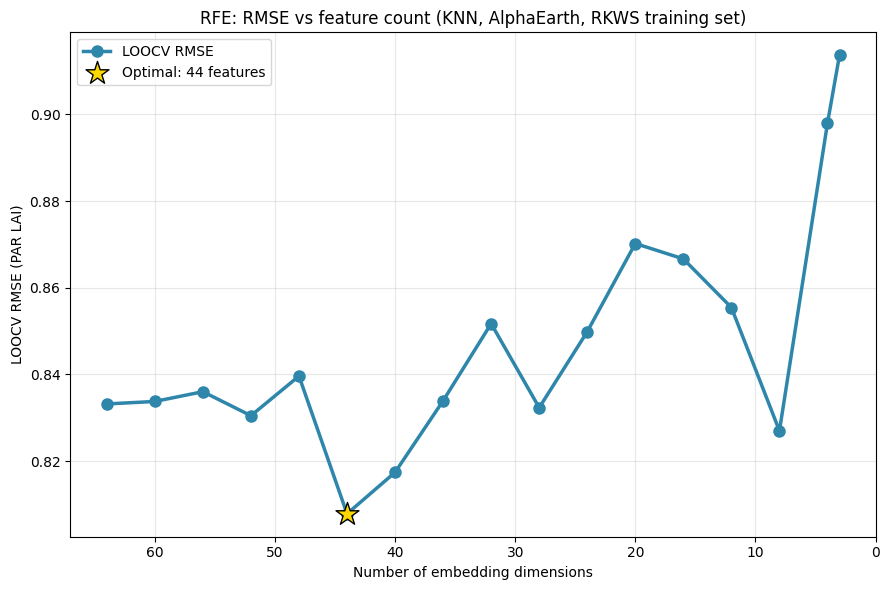

=== RKWS model performance (k-Nearest Neighbours (KNN), AlphaEarth embeddings) ===
                        Set  N    R2  RMSE   MAE  rRMSE (%)  Bias (mean residual)
RKWS Train (in-sample, KNN) 47 1.000 0.000 0.000        0.0                  0.00
  RKWS Test (held-out, KNN) 12 0.081 0.858 0.659       39.6                  0.08

=== Per-plot residuals (RKWS test set) ===
 cluster_id  observed_par_lai  predicted_par_lai  residual
          5             0.331              2.381     2.050
          4             2.068              2.540     0.472
         42             1.949              2.325     0.376
         14             1.625              1.930     0.305
         56             3.174              2.267    -0.907
         46             0.984              1.471     0.487
         45             2.310              2.138    -0.173
         31             1.741              2.484     0.743
         58             2.359              2.262    -0.097
         13             2.841        

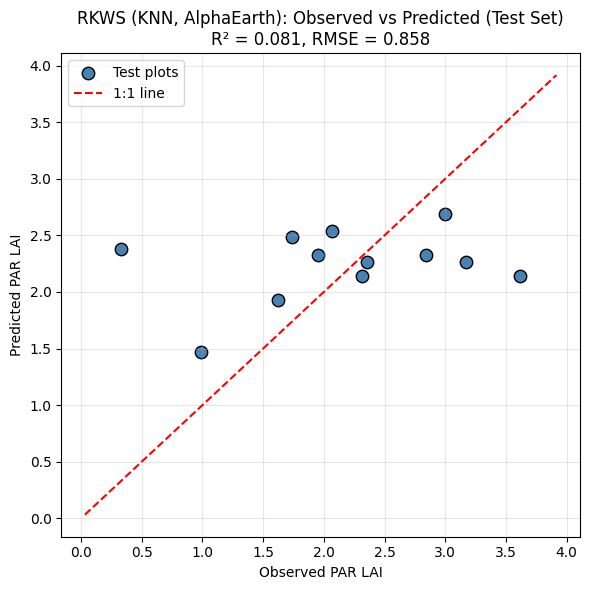

=== Spatial transfer performance (RKWS -> KNP, k-Nearest Neighbours (KNN), AlphaEarth) ===
                                 Set  N     R2  RMSE   MAE  rRMSE (%)  Bias (mean residual)
Transfer: RKWS KNN -> KNP (40 plots) 40 -0.013 1.216 1.023       49.8                -0.108

=== Per-plot residuals (KNP, spatial transfer) ===
cluster_id  observed_par_lai  predicted_par_lai  residual
        20             1.671              2.028     0.358
         2             3.039              1.994    -1.045
        27             2.155              2.433     0.279
        40             0.285              2.129     1.844
        11             3.924              2.246    -1.678
        13             3.148              1.861    -1.287
        25             4.924              2.234    -2.690
        32             1.538              2.346     0.808
        33             3.216              2.610    -0.606
        36             3.480              2.048    -1.432
        38             2.537       

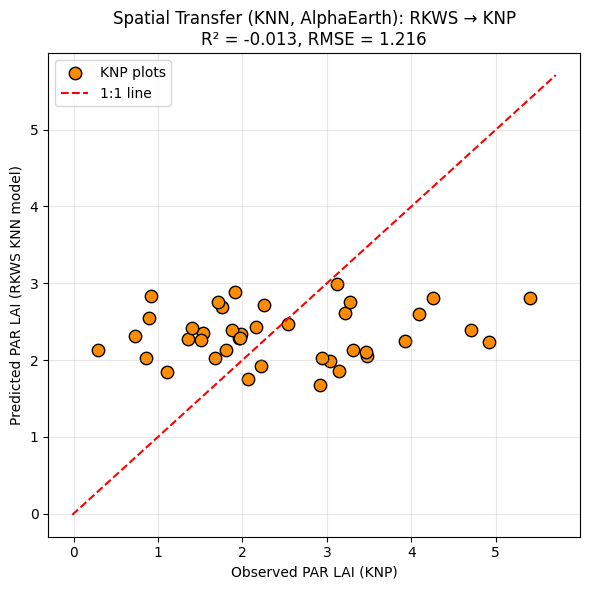

In [2]:
# ============================================================
# PAR LAI FROM ALPHAEARTH SATELLITE EMBEDDINGS  |  k-Nearest Neighbours (KNN)
# Training/testing: Rema-Kalenga Wildlife Sanctuary (RKWS, field 2021)
# Spatial transfer: Khadimnagar National Park (KNP, field 2022)
# Predictors: GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL (64 bands, A00-A63, 10 m)
# ============================================================

# %% SETUP
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'earthengine-api', 'rasterio', 'xgboost'], check=False)

import ee
ee.Authenticate()
ee.Initialize(project='osmgee')

from google.colab import drive
drive.mount('/content/drive')             # mounted up front so every output goes to Drive

import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, LeaveOneOut, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# %% CONFIG
MODEL_TAG  = 'KNN'                  # used in file names and plot labels
MODEL_NAME = 'k-Nearest Neighbours (KNN)'

RKWS_YEAR = 2021                        # RKWS field campaign year
KNP_YEAR  = 2022                        # KNP field campaign year
EMB_COLLECTION = 'GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL'
EMB_BANDS = [f'A{i:02d}' for i in range(64)]

# Recursive feature elimination on the 64 embedding dimensions.
# Google recommends using all 64 bands together (they are one 64-D vector, not
# individually interpretable). Set USE_RFE = False to keep all 64.
USE_RFE            = True
RFE_MIN_FEATURES   = 3
RFE_STEP           = 4                  # dimensions removed per iteration (64 -> ~16 iterations)
RFE_DROP_THRESHOLD = 0.15               # stop if LOOCV RMSE rises by more than this (LAI units)

# Every output file name carries RUN_TAG, so RFE and all-64 runs never overwrite each other
RUN_TAG = f'{MODEL_TAG}_{"RFE" if USE_RFE else "all64"}'     # e.g. KNN_all64, KNN_RFE

DRIVE_FOLDER = 'GEE_Exports'            # export folder AND the folder read back from Drive
base = f'/content/drive/MyDrive/{DRIVE_FOLDER}/'
import os
os.makedirs(base, exist_ok=True)

# %% [GEE] STUDY AREAS AND FIELD PLOTS
rema_boundary = ee.FeatureCollection('projects/osmgee/assets/RemaKalenga')
rema_sites    = ee.FeatureCollection('projects/osmgee/assets/RemaSites')
knp_boundary  = ee.FeatureCollection('projects/osmgee/assets/KNP')
knp_sites     = ee.FeatureCollection('projects/osmgee/assets/SitesLocation')

def clean_feature(f):
    lon = ee.Number(f.get('XCoord'))
    lat = ee.Number(f.get('YCoord'))
    return ee.Feature(
        ee.Geometry.Point([lon, lat]),
        {'cluster_id': f.get('ClusterID'),
         'par_lai': ee.Number(f.get('MEAN_PAR_L')),
         'longitude': lon,
         'latitude': lat}
    )

def make_square_plot(feature):
    # 15 m x 15 m plot centred on the field point
    return feature.setGeometry(feature.geometry().buffer(7.5, 1).bounds())

rema_squares = rema_sites.map(clean_feature).map(make_square_plot)
knp_squares  = knp_sites.map(clean_feature).map(make_square_plot)

print('RKWS plots:', rema_squares.size().getInfo())
print('KNP plots :', knp_squares.size().getInfo())

# %% [GEE] ALPHAEARTH EMBEDDING IMAGES
def get_embedding(boundary, year):
    col = (ee.ImageCollection(EMB_COLLECTION)
           .filterBounds(boundary.geometry())
           .filterDate(f'{year}-01-01', f'{year + 1}-01-01'))
    n = col.size().getInfo()
    zones = col.aggregate_array('UTM_ZONE').distinct().getInfo()
    print(f'  {year}: {n} embedding tile(s), UTM zone(s): {zones}')
    if n == 0:
        raise ValueError(f'No embedding tiles found for {year}')
    proj = col.first().select(0).projection()
    return col.mosaic().select(EMB_BANDS).setDefaultProjection(proj).clip(boundary)

print('RKWS embedding:')
emb_rema = get_embedding(rema_boundary, RKWS_YEAR)
print('KNP embedding:')
emb_knp = get_embedding(knp_boundary, KNP_YEAR)

# %% [GEE] EXTRACT MEAN EMBEDDING PER 15 m PLOT
id_cols = ['cluster_id', 'par_lai', 'longitude', 'latitude']

def extract_plot_means(image, squares, label):
    fc = image.reduceRegions(collection=squares, reducer=ee.Reducer.mean(), scale=10)
    df = pd.DataFrame([f['properties'] for f in fc.getInfo()['features']])
    df = df[id_cols + EMB_BANDS]
    n0 = len(df)
    df = df.dropna(subset=EMB_BANDS + ['par_lai']).reset_index(drop=True)
    print(f'{label}: {len(df)} plots extracted' +
          (f' ({n0 - len(df)} dropped: no embedding data)' if len(df) < n0 else ''))
    return df

df_rema = extract_plot_means(emb_rema, rema_squares, 'RKWS')
df_knp  = extract_plot_means(emb_knp,  knp_squares,  'KNP')
df_rema.head()

# %% TRAIN / TEST SPLIT (80/20, same seed as the Sentinel-2 and PlanetScope runs)
X_rema = df_rema[EMB_BANDS]
y_rema = df_rema['par_lai']

X_train_rema, X_test_rema, y_train_rema, y_test_rema = train_test_split(
    X_rema, y_rema, test_size=0.2, random_state=42
)

print(f'Train: {len(y_train_rema)} plots | Test: {len(y_test_rema)} plots')
print('Test cluster IDs (compare with the Sentinel-2 run):',
      sorted(df_rema.loc[X_test_rema.index, 'cluster_id'].tolist()))
print('Train PAR LAI range:', round(y_train_rema.min(), 2), '-', round(y_train_rema.max(), 2),
      '| mean', round(y_train_rema.mean(), 2))
print('Test PAR LAI range :', round(y_test_rema.min(), 2), '-', round(y_test_rema.max(), 2),
      '| mean', round(y_test_rema.mean(), 2))

# %% MODEL DEFINITION (k-Nearest Neighbours (KNN))

# 'scale' tests raw embeddings (their native geometry, already unit-length)
# against standardised ones; 'cosine' is the natural metric for embeddings.
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'cosine'],
    'scale': [False, True],
}

def make_model(params):
    params = dict(params)
    scale = params.pop('scale')
    return Pipeline([('scaler', StandardScaler() if scale else 'passthrough'),
                     ('knn', KNeighborsRegressor(algorithm='brute', **params))])

def feature_importance(model, X, y):
    # Model has no built-in importance: rank dimensions by permutation importance (training set)
    return permutation_importance(model, X, y, n_repeats=10, random_state=42,
                                  scoring='neg_mean_squared_error', n_jobs=-1).importances_mean

# %% HYPERPARAMETER SEARCH VIA LOOCV (all 64 embedding dimensions)
loo = LeaveOneOut()

def loocv_rmse(params, features):
    scores = cross_val_score(make_model(params), X_train_rema[features], y_train_rema,
                             cv=loo, scoring='neg_mean_squared_error', n_jobs=-1)
    return np.sqrt(-scores.mean())

keys = list(param_grid.keys())
param_list = [dict(zip(keys, combo)) for combo in itertools.product(*param_grid.values())]
print(f'Total hyperparameter combinations to test: {len(param_list)}')

start_time = time.time()
search_results = []
for i, params in enumerate(param_list, 1):
    search_results.append({**params, 'loocv_rmse': loocv_rmse(params, EMB_BANDS)})
    if i % 20 == 0:
        print(f'  {i}/{len(param_list)} done ({(time.time() - start_time)/60:.1f} min)')

results_df = pd.DataFrame(search_results)
best_idx = int(results_df['loocv_rmse'].idxmin())
best_params = param_list[best_idx]

print(f'\nTop 5 combinations by LOOCV RMSE ({MODEL_TAG}, AlphaEarth):')
print(results_df.sort_values('loocv_rmse').head(5).to_string(index=False))
print('\nBest hyperparameters:', best_params)

# %% RECURSIVE FEATURE ELIMINATION (training set only, LOOCV)
current_features = EMB_BANDS.copy()
rfe_results = []

if USE_RFE:
    print('\n' + '=' * 60)
    print(f'STARTING RFE ({MODEL_TAG}, RKWS training set, LOOCV)')
    print('=' * 60)
    start_time = time.time()
    iteration = 0

    while True:
        iteration += 1
        rmse = loocv_rmse(best_params, current_features)
        baseline = rfe_results[0]['rmse'] if rfe_results else rmse
        increase = rmse - baseline
        print(f'Iteration {iteration}: {len(current_features)} features -> '
              f'LOOCV RMSE = {rmse:.3f} (change from baseline: {increase:+.3f})')

        rfe_results.append({'iteration': iteration, 'n_features': len(current_features),
                            'features': current_features.copy(), 'rmse': rmse,
                            'rmse_increase': increase})

        if len(rfe_results) > 1 and increase > RFE_DROP_THRESHOLD:
            print(f'  STOPPING: RMSE rose by {increase:.3f} (threshold {RFE_DROP_THRESHOLD})')
            break
        if len(current_features) <= RFE_MIN_FEATURES:
            print(f'  STOPPING: reached minimum feature count ({RFE_MIN_FEATURES})')
            break

        model = make_model(best_params).fit(X_train_rema[current_features], y_train_rema)
        imp = feature_importance(model, X_train_rema[current_features], y_train_rema)
        ranked = [f for _, f in sorted(zip(imp, current_features))]   # least important first
        n_remove = min(RFE_STEP, len(current_features) - RFE_MIN_FEATURES)
        to_remove = ranked[:n_remove]
        print(f'  Removing: {to_remove}')
        current_features = [f for f in current_features if f not in to_remove]

    best_rfe = min(rfe_results, key=lambda r: r['rmse'])
    selected_features = best_rfe['features']

    print('\n' + '=' * 60)
    print(f'RFE COMPLETE in {(time.time() - start_time)/60:.1f} min')
    print(f'Optimal feature count: {best_rfe["n_features"]}')
    print(f'Optimal features: {selected_features}')
    print(f'Optimal LOOCV RMSE: {best_rfe["rmse"]:.3f} (baseline {rfe_results[0]["rmse"]:.3f})')

    rfe_df = pd.DataFrame(rfe_results)
    plt.figure(figsize=(9, 6))
    plt.plot(rfe_df['n_features'], rfe_df['rmse'], marker='o', markersize=8,
             linewidth=2.5, color='#2E86AB', label='LOOCV RMSE')
    b = rfe_df['rmse'].idxmin()
    plt.scatter(rfe_df.loc[b, 'n_features'], rfe_df.loc[b, 'rmse'], color='gold', s=300,
                marker='*', zorder=5, edgecolor='black',
                label=f'Optimal: {rfe_df.loc[b, "n_features"]} features')
    plt.xlabel('Number of embedding dimensions')
    plt.ylabel('LOOCV RMSE (PAR LAI)')
    plt.title(f'RFE: RMSE vs feature count ({MODEL_TAG}, AlphaEarth, RKWS training set)')
    plt.gca().invert_xaxis()
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    selected_features = EMB_BANDS.copy()
    print('RFE skipped: using all 64 embedding dimensions')

# %% FINAL MODEL: FIT ON TRAINING SET, EVALUATE ON HELD-OUT TEST SET
def compute_metrics(y_true, y_pred, label):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {
        'Set': label,
        'N': len(y_true),
        'R2': round(r2_score(y_true, y_pred), 3),
        'RMSE': round(rmse, 3),
        'MAE': round(mean_absolute_error(y_true, y_pred), 3),
        'rRMSE (%)': round(rmse / y_true.mean() * 100, 1),
        'Bias (mean residual)': round((y_pred - y_true).mean(), 3),
    }

final_model = make_model(best_params)
final_model.fit(X_train_rema[selected_features], y_train_rema)

y_pred_train_rema = final_model.predict(X_train_rema[selected_features])
y_pred_test_rema  = final_model.predict(X_test_rema[selected_features])

metrics_df_rema = pd.DataFrame([
    compute_metrics(y_train_rema, y_pred_train_rema, f'RKWS Train (in-sample, {MODEL_TAG})'),
    compute_metrics(y_test_rema,  y_pred_test_rema,  f'RKWS Test (held-out, {MODEL_TAG})'),
])
print(f'=== RKWS model performance ({MODEL_NAME}, AlphaEarth embeddings) ===')
print(metrics_df_rema.to_string(index=False))
print()

residuals_df_rema = pd.DataFrame({
    'cluster_id': df_rema.loc[X_test_rema.index, 'cluster_id'].values,
    'observed_par_lai': y_test_rema.values.round(3),
    'predicted_par_lai': y_pred_test_rema.round(3),
    'residual': (y_pred_test_rema - y_test_rema.values).round(3),
})
print('=== Per-plot residuals (RKWS test set) ===')
print(residuals_df_rema.to_string(index=False))
print()

# --- Normalized permutation importance on the held-out test set (0-100) ---
perm = permutation_importance(final_model, X_test_rema[selected_features], y_test_rema,
                              n_repeats=30, random_state=42, scoring='r2')
imp_raw = perm.importances_mean
imp_clip = np.clip(imp_raw, 0, None)
imp_norm = imp_clip / imp_clip.max() * 100 if imp_clip.max() > 0 else imp_clip

importance_df = pd.DataFrame({
    'Feature': selected_features,
    'Raw_Importance': imp_raw.round(4),
    'Normalized_Importance (0-100)': imp_norm.round(1),
}).sort_values('Normalized_Importance (0-100)', ascending=False).reset_index(drop=True)
print(f'=== Normalized permutation importance ({MODEL_TAG}, AlphaEarth; top 15) ===')
print(importance_df.head(15).to_string(index=False))

# --- Observed vs predicted (test set) ---
m_test = metrics_df_rema.iloc[1]
plt.figure(figsize=(6, 6))
plt.scatter(y_test_rema, y_pred_test_rema, color='steelblue', edgecolor='black', s=80,
            label='Test plots')
lims = [min(y_test_rema.min(), y_pred_test_rema.min()) - 0.3,
        max(y_test_rema.max(), y_pred_test_rema.max()) + 0.3]
plt.plot(lims, lims, 'r--', label='1:1 line')
plt.xlabel('Observed PAR LAI')
plt.ylabel('Predicted PAR LAI')
plt.title(f'RKWS ({MODEL_TAG}, AlphaEarth): Observed vs Predicted (Test Set)\n'
          f'R² = {m_test["R2"]}, RMSE = {m_test["RMSE"]}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# %% NAIVE SPATIAL TRANSFER: APPLY FROZEN MODEL TO KNP (NO RETRAINING)
y_knp_true = df_knp['par_lai']
y_knp_pred = final_model.predict(df_knp[selected_features])

transfer_metrics_df_knp = pd.DataFrame([compute_metrics(
    y_knp_true, y_knp_pred, f'Transfer: RKWS {MODEL_TAG} -> KNP ({len(df_knp)} plots)')])
print(f'=== Spatial transfer performance (RKWS -> KNP, {MODEL_NAME}, AlphaEarth) ===')
print(transfer_metrics_df_knp.to_string(index=False))
print()

transfer_residuals_df_knp = pd.DataFrame({
    'cluster_id': df_knp['cluster_id'],
    'observed_par_lai': y_knp_true.round(3),
    'predicted_par_lai': y_knp_pred.round(3),
    'residual': (y_knp_pred - y_knp_true).round(3),
})
print('=== Per-plot residuals (KNP, spatial transfer) ===')
print(transfer_residuals_df_knp.to_string(index=False))

m_tr = transfer_metrics_df_knp.iloc[0]
plt.figure(figsize=(6, 6))
plt.scatter(y_knp_true, y_knp_pred, color='darkorange', edgecolor='black', s=80, label='KNP plots')
lims = [min(y_knp_true.min(), y_knp_pred.min()) - 0.3, max(y_knp_true.max(), y_knp_pred.max()) + 0.3]
plt.plot(lims, lims, 'r--', label='1:1 line')
plt.xlabel('Observed PAR LAI (KNP)')
plt.ylabel(f'Predicted PAR LAI (RKWS {MODEL_TAG} model)')
plt.title(f'Spatial Transfer ({MODEL_TAG}, AlphaEarth): RKWS → KNP\n'
          f'R² = {m_tr["R2"]}, RMSE = {m_tr["RMSE"]}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



In [3]:
# --- Save all tables ---
metrics_df_rema.to_csv(base + f'AEF_{RUN_TAG}_RKWS_metrics.csv', index=False)
transfer_metrics_df_knp.to_csv(base + f'AEF_{RUN_TAG}_KNP_transfer_metrics.csv', index=False)
residuals_df_rema.to_csv(base + f'AEF_{RUN_TAG}_RKWS_test_residuals.csv', index=False)
transfer_residuals_df_knp.to_csv(base + f'AEF_{RUN_TAG}_KNP_residuals.csv', index=False)
importance_df.to_csv(base + f'AEF_{RUN_TAG}_importance.csv', index=False)

# %% [GEE] EXPORT EMBEDDING COMPOSITES (SELECTED DIMENSIONS) TO DRIVE
export_names = {
    'RKWS': f'RKWS_AEF{RKWS_YEAR}_{RUN_TAG}_features',
    'KNP':  f'KNP_AEF{KNP_YEAR}_{RUN_TAG}_features',
}

# Stop early if a file with the same name is already in Drive: Drive never overwrites,
# it saves the new export as "name (1).tif" and the script would read the old file
for name in export_names.values():
    if os.path.exists(base + name + '.tif'):
        raise FileExistsError(f'{name}.tif already exists in {DRIVE_FOLDER}. Delete it in Drive '
                              'first (plus any "(1)" copies), or change RUN_TAG.')
tasks = []
for site, img, bnd in [('RKWS', emb_rema, rema_boundary), ('KNP', emb_knp, knp_boundary)]:
    task = ee.batch.Export.image.toDrive(
        image=img.select(selected_features).toFloat(),   # band order = selected_features
        description=export_names[site],
        folder=DRIVE_FOLDER,
        fileNamePrefix=export_names[site],
        region=bnd.geometry(),
        scale=10,
        crs='EPSG:4326',
        maxPixels=1e13,
    )
    task.start()
    tasks.append(task)
    print('Started export:', export_names[site], f'({len(selected_features)} bands)')

# Wait for both exports (re-run this loop if Colab times out)
while any(t.status()['state'] in ('READY', 'RUNNING') for t in tasks):
    print('  ' + ' | '.join(f"{t.status()['description']}: {t.status()['state']}" for t in tasks))
    time.sleep(30)
for t in tasks:
    s = t.status()
    print(s['description'], '->', s['state'], s.get('error_message', ''))

# %% [DRIVE] PREDICT LAI MAPS FROM THE EXPORTED RASTERS
import rasterio
drive.mount('/content/drive', force_remount=True)   # refresh so the new exports are visible
for name in export_names.values():
    if not os.path.exists(base + name + '.tif'):
        raise FileNotFoundError(f'{name}.tif not in Drive yet: wait a minute and re-run this cell')

def predict_lai_map(tif_path, out_path, model, feature_names):
    with rasterio.open(tif_path) as src:
        arr = src.read().astype('float32')            # (bands, rows, cols)
        profile = src.profile
    n_bands, rows, cols = arr.shape
    assert n_bands == len(feature_names), f'Band count {n_bands} != feature count {len(feature_names)}'

    X = arr.reshape(n_bands, -1).T                     # (pixels, bands)
    valid = np.all(np.isfinite(X), axis=1)
    pred = np.full(X.shape[0], np.nan, dtype='float32')
    pred[valid] = model.predict(pd.DataFrame(X[valid], columns=feature_names))
    lai_map = pred.reshape(rows, cols)

    profile.update(count=1, dtype='float32', nodata=np.nan, compress='lzw')
    with rasterio.open(out_path, 'w', **profile) as dst:
        dst.write(lai_map, 1)
    return lai_map

lai_rkws = predict_lai_map(base + export_names['RKWS'] + '.tif',
                           base + f'RKWS_LAI_pred_AEF_{RUN_TAG}.tif',
                           final_model, selected_features)
lai_knp = predict_lai_map(base + export_names['KNP'] + '.tif',
                          base + f'KNP_LAI_pred_AEF_{RUN_TAG}.tif',
                          final_model, selected_features)      # frozen model, no retraining

# --- Quick-look maps (aspect-corrected for geographic pixels) ---
def pixel_size_m(path):
    with rasterio.open(path) as src:
        dx, dy = src.transform.a, -src.transform.e
        if src.crs.is_geographic:
            lat0 = np.radians((src.bounds.top + src.bounds.bottom) / 2)
            return dx * 111320 * np.cos(lat0), dy * 111320
        return dx, dy

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, m, site, label in zip(axes, [lai_rkws, lai_knp], ['RKWS', 'KNP'], ['(a)', '(b)']):
    mx, my = pixel_size_m(base + export_names[site] + '.tif')
    im = ax.imshow(m, cmap='YlGn', vmin=0, vmax=6, aspect=my / mx)
    ax.axis('off')
    ax.set_anchor('N')
    ax.text(0.02, 0.98, label, transform=ax.transAxes, fontsize=16,
            fontweight='bold', va='top', ha='left')
fig.colorbar(im, ax=axes, shrink=0.7, label=f'Predicted PAR LAI (AlphaEarth, {MODEL_TAG})')
plt.savefig(base + f'LAI_maps_RKWS_KNP_AEF_{RUN_TAG}.png', dpi=300,
            bbox_inches='tight', facecolor='white')
plt.show()

# %% [DRIVE] SUMMARY STATISTICS OF PREDICTED LAI MAPS
map_rows = []
for site, m in [('RKWS', lai_rkws), ('KNP', lai_knp)]:
    mx, my = pixel_size_m(base + export_names[site] + '.tif')
    vals = m[np.isfinite(m)]
    map_rows.append({
        'Predictors (model)': f'AlphaEarth ({RUN_TAG})', 'Site': site,
        'Area (ha)': round(len(vals) * mx * my / 10000, 1),
        'Min': round(vals.min(), 2), 'Max': round(vals.max(), 2),
        'Range': round(vals.max() - vals.min(), 2),
        'Mean': round(vals.mean(), 2), 'SD': round(vals.std(), 2),
        'CV (%)': round(vals.std() / vals.mean() * 100, 1),
    })
map_stats_df = pd.DataFrame(map_rows)
print(f'=== Predicted LAI summary (AlphaEarth, {MODEL_TAG}) ===')
print(map_stats_df.to_string(index=False))
map_stats_df.to_csv(base + f'LAI_summary_stats_AEF_{RUN_TAG}.csv', index=False)

FileExistsError: RKWS_AEF2021_KNN_RFE_features.tif already exists in GEE_Exports. Delete it in Drive first (plus any "(1)" copies), or change RUN_TAG.